<h3> Descompactando e extraindo os arquivos da base de dados </h3>


In [1]:
import zipfile

arquivo_zip = '/metro+interstate+traffic+volume.zip'

with zipfile.ZipFile(arquivo_zip, 'r') as zip_ref:
    zip_ref.extractall('/content/metro_traffic')

print("Arquivos extraídos com sucesso!")

Arquivos extraídos com sucesso!


<h3> Importando as bibliotecas </h3>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

<h3> Carregando a base de dados CSV compactada em formato GZIP </h3>

In [3]:
caminho = '/content/metro_traffic/Metro_Interstate_Traffic_Volume.csv.gz'

df = pd.read_csv(caminho, compression='gzip')

print("Base carregada com sucesso!")

Base carregada com sucesso!


<h3> Visualizando as primeiras 5 linhas da base de dados </h3>

In [4]:
df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


<h2> Analisando e tratando a base de dados para cálculos </h2>

In [5]:
# quantas colunas e quantas linhas a base de dados tem
df.shape

(48204, 9)

In [6]:
# identificando os tipos de dados da base
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB


In [7]:
# verificando dados ausentes (99% feriados)
df.isnull().sum()

,0
holiday,48143
temp,0
rain_1h,0
snow_1h,0
clouds_all,0
weather_main,0
weather_description,0
date_time,0
traffic_volume,0


In [8]:
df = df.drop(columns=['holiday'])

<h3> Analisando se há dados duplicados e removendo para não afetar as estatísticas </h3>

In [9]:
# Verificando e removendo duplicados
print("Duplicados encontrados:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape após remoção:", df.shape)

Duplicados encontrados: 17
Shape após remoção: (48187, 8)


In [10]:
# pós coluna de feriados ser removida
df.shape

(48187, 8)

In [11]:
# alterando o tipo da coluna data
df['date_time'] = pd.to_datetime(df['date_time'])

In [12]:
# Pegando apenas 200 dos dados fixos
df_amostra = df.sample(n=200, random_state=42)
print("Quantidade de registros:", len(df_amostra))

Quantidade de registros: 200


<h2> Estatísticas descritivas </h2>

In [13]:
def calcular_media(dados):
    soma = sum(dados)
    quantidade = len(dados)
    return soma / quantidade

media = calcular_media(df_amostra['traffic_volume'])
print(f"Média do volume de tráfego: {media:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."))


def calcular_mediana(dados):
    dados_ordenados = sorted(dados)
    tamanho = len(dados_ordenados)
    meio = tamanho // 2

    if tamanho % 2 == 0:
        mediana = (dados_ordenados[meio - 1] + dados_ordenados[meio]) / 2
        return mediana
    else:
        mediana = dados_ordenados[meio]
        return mediana

mediana = calcular_mediana(df_amostra['traffic_volume'])
print(f"Mediana do volume de tráfego: {mediana:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."))


def calcular_moda(dados):
    frequencias = {}

    for valor in dados:
        if valor in frequencias:
            frequencias[valor] += 1
        else:
            frequencias[valor] = 1

    maior_frequencia = max(frequencias.values())

    modas = []

    for valor, frequencia in frequencias.items():
        if frequencia == maior_frequencia:
            modas.append(valor)

    return modas


moda = calcular_moda(df_amostra['traffic_volume'])

print("Moda do volume de tráfego:")
for valor in moda:
    print(valor)

Média do volume de tráfego: 3.406,64
Mediana do volume de tráfego: 3.743,50
Moda do volume de tráfego:
955
1478
930


In [14]:
def calcular_variancia(dados):
    media = calcular_media(dados)
    diferencas = [(x - media) ** 2 for x in dados]
    variancia = sum(diferencas) / len(dados)
    return variancia

variancia = calcular_variancia(df_amostra['traffic_volume'])

print(f"Variância do volume de tráfego: {variancia:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."))

print(f"Desvio padrão do volume de tráfego: {variancia ** 0.5:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."))

Variância do volume de tráfego: 3.910.098,69
Desvio padrão do volume de tráfego: 1.977,40


<h2> Separatrizes </h2>

In [15]:
quartis = df_amostra['traffic_volume'].quantile([0.25, 0.50, 0.75])

print("Quartis do volume de tráfego:")

for porcentagem, valor in quartis.items():
    print(f"{porcentagem:.0%}: {valor:.2f}")

Quartis do volume de tráfego:
25%: 1417.50
50%: 3743.50
75%: 4946.25


In [16]:
decis = df_amostra['traffic_volume'].quantile(
    [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
)

print("Decis do volume de tráfego:")

for porcentagem, valor in decis.items():
    print(f"{porcentagem:.0%}: {valor:.2f}")

Decis do volume de tráfego:
10%: 436.50
20%: 984.20
30%: 1966.80
40%: 3052.20
50%: 3743.50
60%: 4363.60
70%: 4813.50
80%: 5338.20
90%: 5847.70


In [17]:
percentis = df_amostra['traffic_volume'].quantile(
    [i / 100 for i in range(1, 100)]
)

print("Percentis do volume de tráfego:")

for porcentagem, valor in percentis.items():
    print(f"{porcentagem:.0%}: {valor:.2f}")

Percentis do volume de tráfego:
1%: 262.69
2%: 294.66
3%: 314.73
4%: 325.96
5%: 334.95
6%: 343.82
7%: 358.58
8%: 371.76
9%: 408.30
10%: 436.50
11%: 507.36
12%: 613.44
13%: 818.58
14%: 832.60
15%: 863.35
16%: 916.88
17%: 929.32
18%: 939.02
19%: 955.00
20%: 984.20
21%: 1009.11
22%: 1078.66
23%: 1140.73
24%: 1254.44
25%: 1417.50
26%: 1478.00
27%: 1574.25
28%: 1713.36
29%: 1802.64
30%: 1966.80
31%: 2117.63
32%: 2358.44
33%: 2561.03
34%: 2584.30
35%: 2621.70
36%: 2706.96
37%: 2830.42
38%: 2883.26
39%: 2959.96
40%: 3052.20
41%: 3083.44
42%: 3127.70
43%: 3259.77
44%: 3340.08
45%: 3365.10
46%: 3398.62
47%: 3506.61
48%: 3557.76
49%: 3649.91
50%: 3743.50
51%: 3812.45
52%: 3838.64
53%: 3873.40
54%: 4001.54
55%: 4086.85
56%: 4121.04
57%: 4226.95
58%: 4282.08
59%: 4318.35
60%: 4363.60
61%: 4422.53
62%: 4460.26
63%: 4513.77
64%: 4575.60
65%: 4626.20
66%: 4648.34
67%: 4684.50
68%: 4737.24
69%: 4772.78
70%: 4813.50
71%: 4840.19
72%: 4863.60
73%: 4901.94
74%: 4925.82
75%: 4946.25
76%: 5002.96
77%: 5042

<h2> Construção e análise de histogramas </h2>

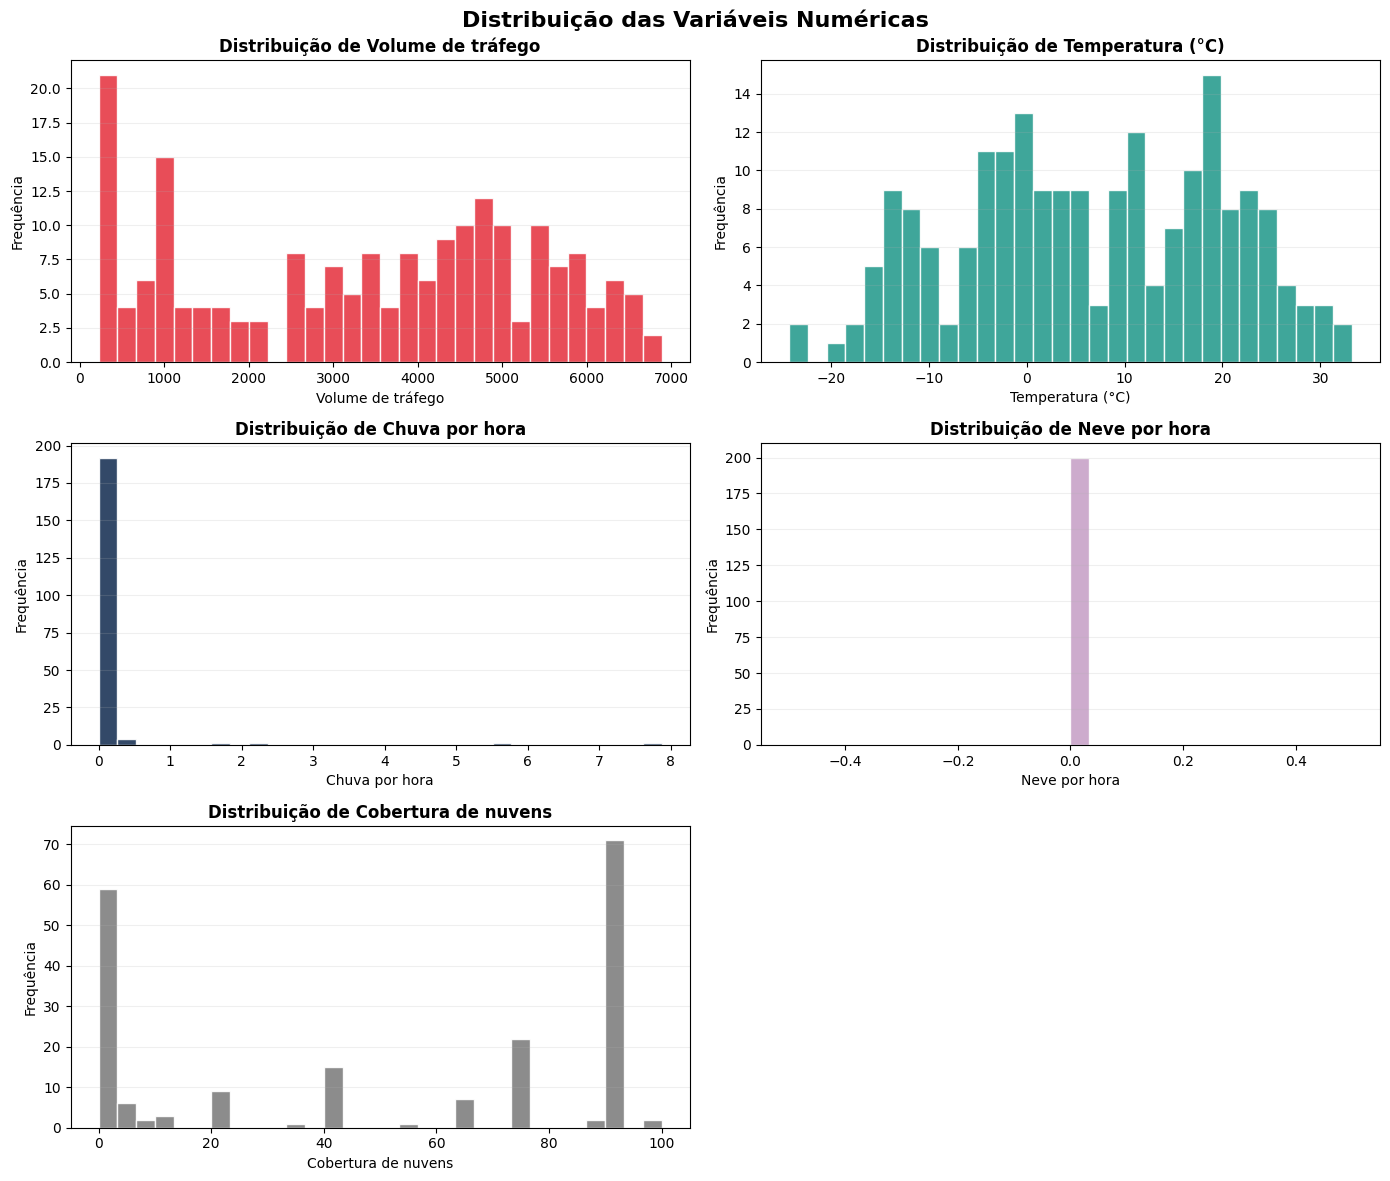

In [18]:
colunas = ['traffic_volume', 'temp', 'rain_1h', 'snow_1h', 'clouds_all']

nomes = [
    'Volume de tráfego',
    'Temperatura (°C)',
    'Chuva por hora',
    'Neve por hora',
    'Cobertura de nuvens'
]

cores = [
    '#E63946',
    '#2A9D8F',
    '#1D3557',
    '#C8A2C8',
    '#808080'
]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()

for i, coluna in enumerate(colunas):

    dados = df_amostra[coluna]

    if coluna == 'temp':
        dados = dados - 273.15

    axes[i].hist(
        dados,
        bins=30,
        edgecolor='white',
        color=cores[i],
        alpha=0.9
    )

    axes[i].set_title(
        f'Distribuição de {nomes[i]}',
        fontsize=12,
        fontweight='bold'
    )
    axes[i].set_xlabel(nomes[i])
    axes[i].set_ylabel('Frequência')
    axes[i].grid(axis='y', alpha=0.2)

fig.delaxes(axes[5])

fig.suptitle(
    'Distribuição das Variáveis Numéricas',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

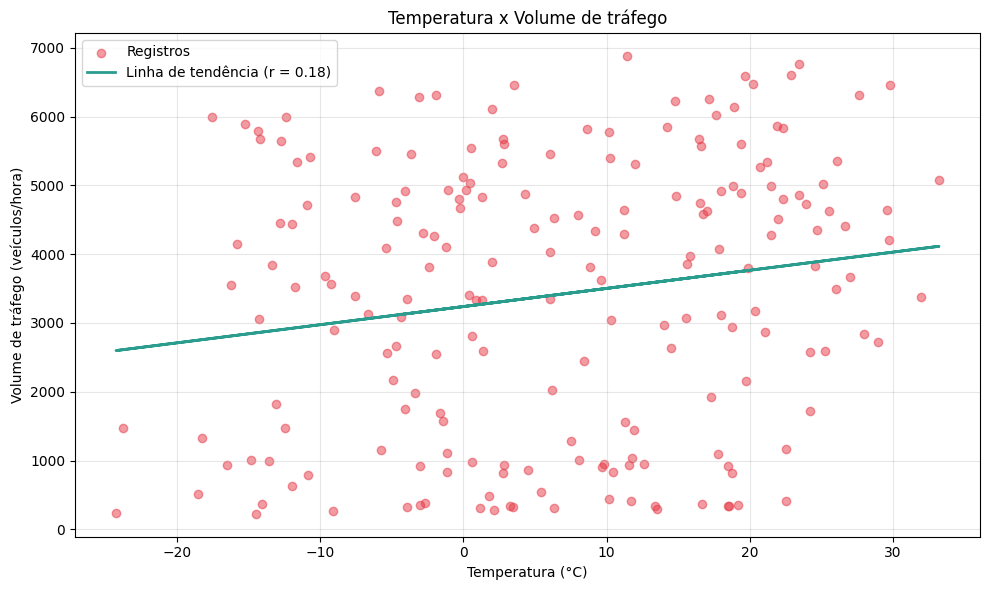

In [19]:
# Conversão de Kelvin para Celsius
x = df_amostra['temp'] - 273.15
y = df_amostra['traffic_volume']

# Cálculo da linha de tendência e correlação
coef = np.polyfit(x, y, 1)
r = np.corrcoef(x, y)[0, 1]

plt.figure(figsize=(10, 6))

# Registros
plt.scatter(x, y, color='#E63946', alpha=0.5, label='Registros')

# Linha de tendência
plt.plot(x, np.poly1d(coef)(x), color='#2A9D8F',
         linewidth=2, label=f'Linha de tendência (r = {r:.2f})')

plt.title('Temperatura x Volume de tráfego')
plt.xlabel('Temperatura (°C)')
plt.ylabel('Volume de tráfego (veículos/hora)')

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

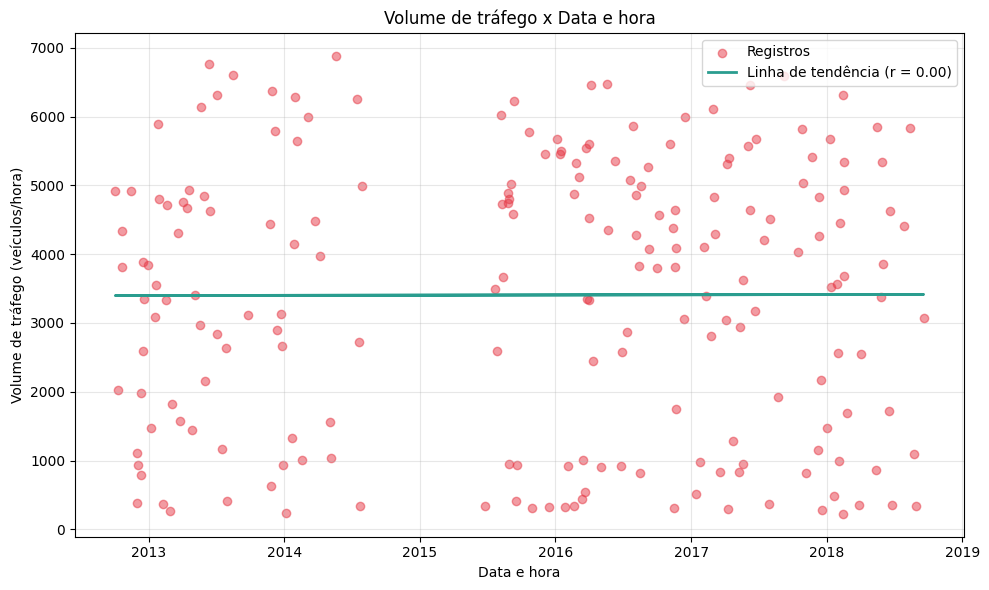

In [21]:
# Conversão de datas para número (necessário para a linha de tendência e correlação)
import matplotlib.dates as mdates

x_data = df_amostra['date_time']
x = mdates.date2num(x_data)
y = df_amostra['traffic_volume']

# Cálculo da linha de tendência e correlação
coef = np.polyfit(x, y, 1)
r = np.corrcoef(x, y)[0, 1]

plt.figure(figsize=(10, 6))

# Registros
plt.scatter(x_data, y, color='#E63946', alpha=0.5, label='Registros')

# Linha de tendência
plt.plot(x_data, np.poly1d(coef)(x), color='#2A9D8F',
         linewidth=2, label=f'Linha de tendência (r = {r:.2f})')

plt.title('Volume de tráfego x Data e hora')
plt.xlabel('Data e hora')
plt.ylabel('Volume de tráfego (veículos/hora)')

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()